# Train on Kaggle (free GPU)

1. Create a new Kaggle notebook → **Add data** → competition *rsna-pneumonia-detection-challenge*.
2. Settings → Accelerator **GPU T4 x2** (or P100), Internet **On**.
3. Upload this repo as a Kaggle *Dataset* (zip it, without `data/` and `models/`) named `medimg-capstone`, and add it too — or `git clone` it if it is on GitHub.
4. Run all cells (~1–2 h for 12 epochs at 320 px). Download `models/classifier.pt`, `metrics/`, `reports/` from the Output tab.

In [3]:

import os

print("Available Kaggle inputs:")

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    print("Folders:", dirs)
    print("Files:", files[:10])
    print("-" * 50)


Available Kaggle inputs:
/kaggle/input
Folders: ['competitions', 'datasets']
Files: []
--------------------------------------------------
/kaggle/input/competitions
Folders: ['rsna-pneumonia-detection-challenge']
Files: []
--------------------------------------------------
/kaggle/input/competitions/rsna-pneumonia-detection-challenge
Folders: ['stage_2_train_images', 'stage_2_test_images']
Files: ['stage_2_sample_submission.csv', 'stage_2_detailed_class_info.csv', 'GCP Credits Request Link - RSNA.txt', 'stage_2_train_labels.csv']
--------------------------------------------------
/kaggle/input/competitions/rsna-pneumonia-detection-challenge/stage_2_train_images
Folders: []
Files: ['c3b05294-29be-46e4-8a51-96fd211e4ca5.dcm', '6a6ed2c5-d179-4c19-aac7-0d70eb87e024.dcm', '06550cfd-e9d5-415e-bae9-3146329ed9e6.dcm', 'ef9eee29-6bdd-41da-ae40-9473592a9d5c.dcm', 'c5dfc1a7-4669-42ce-af9f-62c3d8322049.dcm', '791e72c5-ecb4-43bc-aeda-7756af052534.dcm', '5c4ca9b6-f749-424e-885f-f2bb896666fb.dcm', 'f

In [4]:

import os

DATASET_DIR = "/kaggle/input/datasets"

for root, dirs, files in os.walk(DATASET_DIR):
    print("Folder:", root)
    print("Subfolders:", dirs)
    print("Files:", files[:10])
    print("-" * 60)


Folder: /kaggle/input/datasets
Subfolders: ['rupjitshil']
Files: []
------------------------------------------------------------
Folder: /kaggle/input/datasets/rupjitshil
Subfolders: ['medimg-capstone']
Files: []
------------------------------------------------------------
Folder: /kaggle/input/datasets/rupjitshil/medimg-capstone
Subfolders: ['medimg-capstone']
Files: []
------------------------------------------------------------
Folder: /kaggle/input/datasets/rupjitshil/medimg-capstone/medimg-capstone
Subfolders: ['backend', 'docs', 'frontend', 'ml', 'models', 'notebooks']
Files: ['.dockerignore', '.env.example', '.gitignore', 'README.md', 'docker-compose.yml', 'dvc.yaml', 'params.yaml']
------------------------------------------------------------
Folder: /kaggle/input/datasets/rupjitshil/medimg-capstone/medimg-capstone/backend
Subfolders: ['app', 'tests']
Files: ['Dockerfile', 'requirements.txt']
------------------------------------------------------------
Folder: /kaggle/input/data

In [5]:
import os, shutil, subprocess
SRC = "/kaggle/input/datasets/rupjitshil/medimg-capstone/medimg-capstone"  # or: !git clone https://github.com/<you>/medimg-capstone
WORK = '/kaggle/working/medimg-capstone'
if not os.path.exists(WORK):
    shutil.copytree(SRC, WORK)
os.chdir(WORK)
!pip install -q -e ./ml[train]

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for medai (pyproject.toml) ... done


In [6]:
# Point the prepare stage at the competition data instead of downloading 4 GB
os.makedirs('data/raw', exist_ok=True)
if not os.path.exists('data/raw/rsna'):
    os.symlink('/kaggle/input/rsna-pneumonia-detection-challenge', 'data/raw/rsna')
!ls data/raw/rsna | head

data/raw/rsna


In [8]:

import os
import shutil
from pathlib import Path

SOURCE = Path(
    "/kaggle/input/competitions/rsna-pneumonia-detection-challenge"
)

TARGET = Path("/kaggle/working/medimg-capstone/data/raw/rsna")

# Verify the original competition data
LABELS = SOURCE / "stage_2_train_labels.csv"

print("Competition folder exists:", SOURCE.exists())
print("Labels CSV exists:", LABELS.exists())

if not LABELS.exists():
    print("ERROR: Training labels CSV is missing!")
else:
    # Remove an incorrect existing mount
    if TARGET.is_symlink():
        TARGET.unlink()
    elif TARGET.exists():
        shutil.rmtree(TARGET)

    TARGET.parent.mkdir(parents=True, exist_ok=True)

    # Create correct dataset link
    TARGET.symlink_to(SOURCE, target_is_directory=True)

    print("\nDataset connected successfully!")
    print("Labels file accessible:", (TARGET / "stage_2_train_labels.csv").exists())
    print("Dataset files:", os.listdir(TARGET)[:10])


Competition folder exists: True
Labels CSV exists: True

Dataset connected successfully!
Labels file accessible: True
Dataset files: ['stage_2_train_images', 'stage_2_sample_submission.csv', 'stage_2_detailed_class_info.csv', 'GCP Credits Request Link - RSNA.txt', 'stage_2_train_labels.csv', 'stage_2_test_images']


In [9]:
!python ml/scripts/prepare_rsna.py

100%|█████████████████████████████████████| 26684/26684 [33:17<00:00, 13.36it/s]
label      0     1
split             
test    3101   902
train  14470  4208
val     3101   902
view         AP    PA
split sex            
test  F     759   911
      M    1065  1268
train F    3604  4524
      M    4905  5645
val   F     764   956
      M    1076  1207


In [10]:
import torch; print(torch.cuda.get_device_name(0))
!python ml/scripts/train_classifier.py

Tesla T4
device: cuda
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100%|███████████████████████████████████████| 30.8M/30.8M [00:00<00:00, 178MB/s]
epoch 1/12 (head only): 100%|███████████████| 1168/1168 [01:49<00:00, 10.65it/s]
{'epoch': 1, 'train_loss': 0.8853940250518963, 'val_auroc': 0.8185268181138908, 'sec': 135.85173726081848}
epoch 2/12: 100%|███████████████████████████| 1168/1168 [03:04<00:00,  6.32it/s]
{'epoch': 2, 'train_loss': 0.7884734052191813, 'val_auroc': 0.8663802750132101, 'sec': 209.97760033607483}
epoch 3/12: 100%|███████████████████████████| 1168/1168 [03:04<00:00,  6.33it/s]
{'epoch': 3, 'train_loss': 0.7372482937578855, 'val_auroc': 0.8763749051697077, 'sec': 209.95318794250488}
epoch 4/12: 100%|███████████████████████████| 1168/1168 [03:04<00:00,  6.31it/s]
{'epoch': 4, 'train_loss': 0.7175154840681969, 'val_auroc': 0.8722220355210499, 'sec': 210.31951141357422}
epoch 

# Test-set evaluation — densenet121-rsna-202610301757

- N = 4003, prevalence = 22.5%
- AUROC = 0.881 (95% CI 0.869–0.892)
- ECE = 0.129
- At threshold 0.3056: sensitivity 0.888, specificity 0.6953, PPV 0.4588, NPV 0.9553
- Grad-CAM pointing game: 25.3% of 300 positives

## Subgroups

### sex

| group | n | prevalence | AUROC | sensitivity | specificity |
|---|---|---|---|---|---|
| F | 1670 | 0.223 | 0.8833 | 0.8952 | 0.7042 |
| M | 2333 | 0.227 | 0.8794 | 0.883 | 0.6889 |

### age_band

| group | n | prevalence | AUROC | sensitivity | specificity |
|---|---|---|---|---|---|
| <18 | 3944 | 0.224 | 0.8805 | 0.8856 | 0.6981 |

### view

| group | n | prevalence | AUROC | sensitivity | specificity |
|---|---|---|---|---|---|
| AP | 1824 | 0.387 | 0.8215 | 0.9376 | 0.4191 |
| PA | 2179 | 0.09 | 0.8689 | 0.7107 | 0.8512 |



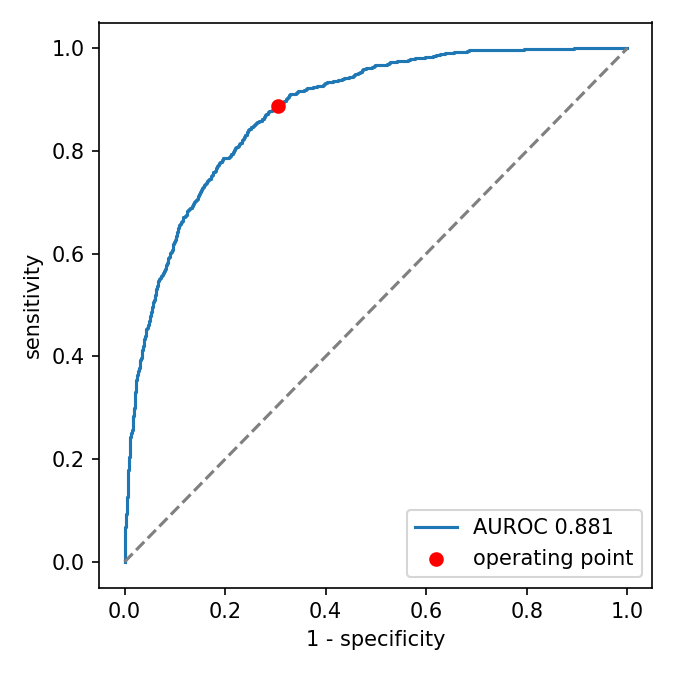

# Test-set evaluation — densenet121-rsna-202610301757

- N = 4003, prevalence = 22.5%
- AUROC = 0.881 (95% CI 0.869–0.892)
- ECE = 0.129
- At threshold 0.3056: sensitivity 0.888, specificity 0.6953, PPV 0.4588, NPV 0.9553
- Grad-CAM pointing game: 25.3% of 300 positives

## Subgroups

### sex

| group | n | prevalence | AUROC | sensitivity | specificity |
|---|---|---|---|---|---|
| F | 1670 | 0.223 | 0.8833 | 0.8952 | 0.7042 |
| M | 2333 | 0.227 | 0.8794 | 0.883 | 0.6889 |

### age_band

| group | n | prevalence | AUROC | sensitivity | specificity |
|---|---|---|---|---|---|
| <18 | 3944 | 0.224 | 0.8805 | 0.8856 | 0.6981 |

### view

| group | n | prevalence | AUROC | sensitivity | specificity |
|---|---|---|---|---|---|
| AP | 1824 | 0.387 | 0.8215 | 0.9376 | 0.4191 |
| PA | 2179 | 0.09 | 0.8689 | 0.7107 | 0.8512 |


In [11]:
!python ml/scripts/evaluate_classifier.py
from IPython.display import Image, Markdown, display
display(Image('reports/roc.png')); display(Markdown(open('reports/eval_cls.md').read()))

## Look at the heatmaps yourself
Review false positives and false negatives — this error analysis is the most valuable chapter of your report.

In [12]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image as PImage
from medai.models import load_checkpoint
from medai.predict import classify
model, meta = load_checkpoint('models/classifier.pt')
df = pd.read_csv('data/processed/rsna/metadata.csv'); te = df[df.split=='test'].sample(8, random_state=1)
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for a, r in zip(ax.flat, te.itertuples()):
    img = np.asarray(PImage.open(f'data/processed/rsna/images/{r.patientId}.png').convert('L'), np.float32)/255
    res = classify(model, meta, img)
    a.imshow(img, cmap='gray'); a.imshow(res.cam, cmap='jet', alpha=0.35)
    a.set_title(f'GT={r.label}  p={res.top_probability:.2f}  {r.view}'); a.axis('off')
plt.tight_layout()

ModuleNotFoundError: No module named 'medai'

In [ ]:
# Optional: 3D U-Net spleen segmentation (~1-2 h). Downloads MSD Task09 (1.5 GB).
# !python ml/scripts/train_segmentation.py